# Tarea 2 — Punto 3: regresión para grasa corporal

Este cuaderno desarrolla el análisis de `bodyfat.txt` mediante regresión Simplex y regresión Beta, usando la edad como predictor. Se presentan la preparación de los datos, las funciones de verosimilitud, la estimación por máxima verosimilitud, la comparación de modelos y una visualización de los ajustes.

> Ejecuta las celdas en orden. `bodyfat.txt` debe encontrarse en el directorio de trabajo del cuaderno. Se conserva la edad en años y se transforma el porcentaje de grasa corporal a una proporción.

## 1. Preparación del entorno

Las dependencias se importan en esta celda. Si falta alguna, se imprime el comando PowerShell correspondiente al intérprete activo del kernel.

In [1]:
import sys
from pathlib import Path

try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy.optimize import minimize
    from scipy.special import expit, gammaln
except ModuleNotFoundError as error:
    print(f"Falta instalar una dependencia: {error}")
    print(f'En PowerShell ejecuta: "{sys.executable}" -m pip install numpy pandas scipy matplotlib seaborn')
    raise

sns.set_theme(style="whitegrid", palette="muted")
print(f"Python del kernel: {sys.executable}")
print(f"Directorio de trabajo: {Path.cwd()}")

Python del kernel: c:\Users\PERSONAL\AppData\Local\Programs\Python\Python314\python.exe
Directorio de trabajo: d:\Escritorio_D\Tarea_2_MLG


## 2. Carga y validación de los datos

El archivo tiene dos columnas sin encabezado: porcentaje de grasa corporal y edad. Se define `y = bodyfat / 100`, de modo que la respuesta sea una proporción. Tanto la distribución Beta como la Simplex estándar requieren observaciones estrictamente interiores, `0 < y < 1`; por ello se verifica esta condición explícitamente y no se corrigen valores de forma silenciosa.

In [2]:
ruta_datos = Path("bodyfat.txt")
if not ruta_datos.is_file():
    raise FileNotFoundError(
        f"No se encontró {ruta_datos.resolve()}. "
        "Coloca bodyfat.txt en el directorio de trabajo del cuaderno."
    )

datos = pd.read_csv(
    ruta_datos,
    sep=r"\s+",
    header=None,
    names=["bodyfat_porcentaje", "edad"],
)
if datos.empty:
    raise ValueError("bodyfat.txt no contiene observaciones.")
if datos.isna().any().any():
    raise ValueError("Hay datos faltantes; revisa el formato de bodyfat.txt.")

datos["y"] = datos["bodyfat_porcentaje"] / 100.0
if not datos["y"].between(0, 1, inclusive="neither").all():
    raise ValueError(
        "Para los modelos Beta y Simplex, cada porcentaje debe estar estrictamente entre 0 y 100. "
        "Revisa las observaciones de bodyfat.txt."
    )

x = datos["edad"].to_numpy(dtype=float)
y = datos["y"].to_numpy(dtype=float)
n = len(y)
print(f"Número de observaciones: {n}")
display(datos.head())
display(datos[["bodyfat_porcentaje", "edad", "y"]].describe().T)

Número de observaciones: 251


,bodyfat_porcentaje,edad,y
0,12.6,23,0.126
1,6.9,22,0.069
2,24.6,22,0.246
3,10.9,26,0.109
4,27.8,24,0.278


,count,mean,std,min,25%,50%,75%,max
bodyfat_porcentaje,251.0,19.013944,7.673049,1.900,13.00,19.00,24.600,45.100
edad,251.0,44.904382,12.623423,22.000,35.50,43.00,54.000,81.000
y,251.0,0.190139,0.076730,0.019,0.13,0.19,0.246,0.451


## 3. Exploración descriptiva

El diagrama de dispersión permite inspeccionar la relación entre edad y proporción de grasa corporal antes de ajustar los modelos. La tendencia observada es descriptiva; la estimación formal de la relación se realiza mediante los modelos probabilísticos de las secciones siguientes.

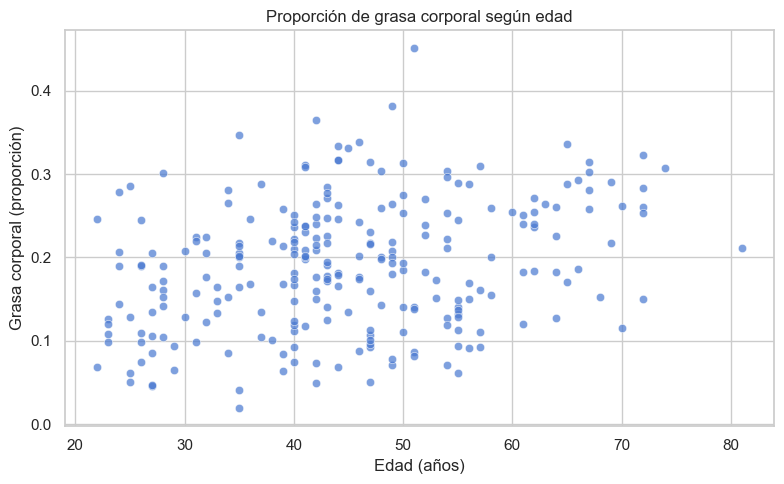

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=datos, x="edad", y="y", alpha=0.7, ax=ax)
ax.set(
    title="Proporción de grasa corporal según edad",
    xlabel="Edad (años)",
    ylabel="Grasa corporal (proporción)",
)
plt.tight_layout()
plt.show()

## 4. Formulación de los modelos

En ambos modelos se usa la misma estructura para la media:

`logit(mu_i) = beta_0 + beta_1 edad_i`, con `logit(mu) = log(mu/(1-mu))`.

Por tanto, `mu_i = logistic(beta_0 + beta_1 edad_i)` queda entre 0 y 1. `beta_1` describe el cambio en el logaritmo de las odds de la media por cada año de edad; `exp(beta_1)` es el factor multiplicativo de esas odds por año. Esto no significa que el porcentaje individual cambie determinísticamente en esa cantidad.

### Modelo Simplex

Para `0 < y_i, mu_i < 1`, la devianza unitaria es `d_i = (y_i-mu_i)^2 / [y_i(1-y_i) mu_i^2(1-mu_i)^2]`. La densidad Simplex tiene log-verosimilitud

`ell_i = -1/2 log(2 pi sigma^2) - 3/2 log[y_i(1-y_i)] - d_i/(2 sigma^2)`.

Se optimiza la negativa de la log-verosimilitud respecto a `beta_0`, `beta_1` y `log(sigma^2)`. La exponencial garantiza `sigma^2 > 0`. Bajo esta parametrización, la varianza condicional es `sigma^2 mu_i^3(1-mu_i)^3`.

### Modelo Beta

Se parametriza `y_i ~ Beta(a_i,b_i)`, con `a_i=mu_i phi` y `b_i=(1-mu_i)phi`. Su media es `mu_i` y su precisión es `phi > 0`; la varianza condicional es `mu_i(1-mu_i)/(phi+1)`. Se estima `log(phi)` junto con los dos coeficientes de la media.

In [4]:
def media_logistica(beta0, beta1, edad):
    """Media de respuesta dada por un predictor lineal con enlace logit."""
    return expit(beta0 + beta1 * edad)


def simplex_nll(parametros):
    """Negativa de la log-verosimilitud Simplex para respuesta interior a (0, 1)."""
    beta0, beta1, log_sigma2 = parametros
    sigma2 = np.exp(log_sigma2)
    mu = np.clip(media_logistica(beta0, beta1, x), 1e-12, 1 - 1e-12)
    devianza = (y - mu) ** 2 / (y * (1 - y) * mu**2 * (1 - mu) ** 2)
    loglik = (
        -0.5 * n * np.log(2 * np.pi * sigma2)
        -1.5 * np.sum(np.log(y * (1 - y)))
        -0.5 / sigma2 * np.sum(devianza)
    )
    return -float(loglik)


def beta_nll(parametros):
    """Negativa de la log-verosimilitud Beta con precisión constante."""
    beta0, beta1, log_phi = parametros
    phi = np.exp(log_phi)
    mu = np.clip(media_logistica(beta0, beta1, x), 1e-12, 1 - 1e-12)
    a = mu * phi
    b = (1 - mu) * phi
    loglik = np.sum(
        gammaln(phi) - gammaln(a) - gammaln(b)
        + (a - 1) * np.log(y)
        + (b - 1) * np.log1p(-y)
    )
    return -float(loglik)


# Verificar que las expresiones entregan valores finitos en los puntos iniciales.
inicio_simplex = np.array([-1.5, 0.01, np.log(0.1)])
inicio_beta = np.array([-1.5, 0.01, np.log(20.0)])
assert np.isfinite(simplex_nll(inicio_simplex))
assert np.isfinite(beta_nll(inicio_beta))
print(f"NLL Simplex en punto inicial: {simplex_nll(inicio_simplex):.4f}")
print(f"NLL Beta en punto inicial: {beta_nll(inicio_beta):.4f}")

NLL Simplex en punto inicial: 3501.2213
NLL Beta en punto inicial: -221.8625


## 5. Estimación por máxima verosimilitud

La estimación de máxima verosimilitud minimiza la negativa de cada log-verosimilitud. Se utiliza BFGS y se muestran el estado y mensaje del optimizador para no ocultar una posible falta de convergencia. Las optimizaciones parten de valores iniciales razonables; los parámetros de dispersión/precisión se expresan en escala logarítmica.

In [5]:
ajuste_simplex = minimize(simplex_nll, inicio_simplex, method="BFGS")
ajuste_beta = minimize(beta_nll, inicio_beta, method="BFGS")

for nombre, ajuste in [("Simplex", ajuste_simplex), ("Beta", ajuste_beta)]:
    print(f"{nombre}: convergio={ajuste.success}; mensaje={ajuste.message}")
    if not np.isfinite(ajuste.fun):
        raise RuntimeError(f"La optimización del modelo {nombre} produjo una log-verosimilitud no finita.")

beta0_s, beta1_s, log_sigma2 = ajuste_simplex.x
sigma2 = np.exp(log_sigma2)
beta0_b, beta1_b, log_phi = ajuste_beta.x
phi = np.exp(log_phi)

parametros = pd.DataFrame(
    [
        {"modelo": "Simplex", "beta_0": beta0_s, "beta_1": beta1_s, "dispersion sigma^2": sigma2, "precision phi": np.nan},
        {"modelo": "Beta", "beta_0": beta0_b, "beta_1": beta1_b, "dispersion sigma^2": np.nan, "precision phi": phi},
    ]
)
display(parametros.round(6))

print(f"Simplex: exp(beta_1) = {np.exp(beta1_s):.6f} (factor de odds de la media por año)")
print(f"Beta:    exp(beta_1) = {np.exp(beta1_b):.6f} (factor de odds de la media por año)")

Simplex: convergio=True; mensaje=Optimization terminated successfully.
Beta: convergio=False; mensaje=Desired error not necessarily achieved due to precision loss.


,modelo,beta_0,beta_1,dispersion sigma^2,precision phi
0,Simplex,-2.013176,0.012064,2.30195,NaN
1,Beta,-1.988100,0.011787,NaN,25.262706


Simplex: exp(beta_1) = 1.012137 (factor de odds de la media por año)
Beta:    exp(beta_1) = 1.011856 (factor de odds de la media por año)


## 6. Comparación mediante AIC y BIC

Cada modelo estima tres parámetros: intercepto, pendiente y parámetro de dispersión o precisión. Con `k=3`, `AIC = -2 ell_hat + 2k` y `BIC = -2 ell_hat + k log(n)`. Se comparan los criterios solo porque ambos modelos se ajustan a las mismas observaciones y a la misma respuesta en la misma escala. Menores valores indican mejor equilibrio entre verosimilitud y complejidad dentro de esta comparación; estos criterios no son pruebas de hipótesis.

In [6]:
k = 3
tabla_modelos = pd.DataFrame(
    [
        {"modelo": "Simplex", "log-verosimilitud": -ajuste_simplex.fun, "n_parametros": k,
         "AIC": 2 * ajuste_simplex.fun + 2 * k,
         "BIC": 2 * ajuste_simplex.fun + k * np.log(n)},
        {"modelo": "Beta", "log-verosimilitud": -ajuste_beta.fun, "n_parametros": k,
         "AIC": 2 * ajuste_beta.fun + 2 * k,
         "BIC": 2 * ajuste_beta.fun + k * np.log(n)},
    ]
).set_index("modelo")
display(tabla_modelos.round(4))

delta_aic = tabla_modelos.loc["Simplex", "AIC"] - tabla_modelos.loc["Beta", "AIC"]
delta_bic = tabla_modelos.loc["Simplex", "BIC"] - tabla_modelos.loc["Beta", "BIC"]
print(f"Delta AIC (Simplex - Beta): {delta_aic:.4f}")
print(f"Delta BIC (Simplex - Beta): {delta_bic:.4f}")
if delta_aic > 0 and delta_bic > 0:
    print("Ambos criterios favorecen al modelo Beta para estos datos.")
elif delta_aic < 0 and delta_bic < 0:
    print("Ambos criterios favorecen al modelo Simplex para estos datos.")
else:
    print("AIC y BIC no coinciden; la preferencia depende del criterio usado.")

,log-verosimilitud,n_parametros,AIC,BIC
modelo,,,,
Simplex,282.7435,3,-559.4871,-548.9107
Beta,299.6158,3,-593.2316,-582.6552


Delta AIC (Simplex - Beta): 33.7445
Delta BIC (Simplex - Beta): 33.7445
Ambos criterios favorecen al modelo Beta para estos datos.


## 7. Visualización de las medias ajustadas

Se superponen al diagrama de dispersión las curvas de media estimadas por ambos modelos. Las curvas representan `E(y | edad)` bajo los ajustes y no intervalos de predicción ni observaciones simuladas.

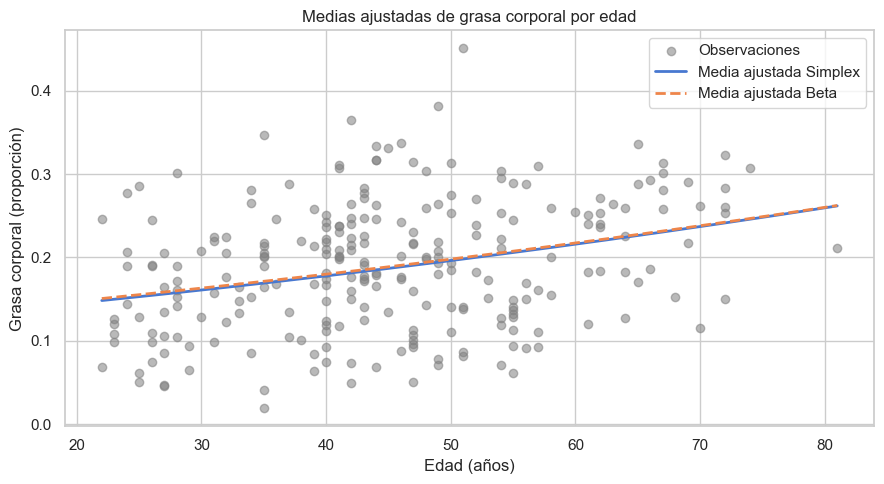

In [7]:
edades = np.linspace(x.min(), x.max(), 250)
media_simplex = media_logistica(beta0_s, beta1_s, edades)
media_beta = media_logistica(beta0_b, beta1_b, edades)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x, y, alpha=0.55, label="Observaciones", color="gray")
ax.plot(edades, media_simplex, linewidth=2, label="Media ajustada Simplex")
ax.plot(edades, media_beta, linewidth=2, linestyle="--", label="Media ajustada Beta")
ax.set(
    title="Medias ajustadas de grasa corporal por edad",
    xlabel="Edad (años)",
    ylabel="Grasa corporal (proporción)",
)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Conclusión

La tabla de parámetros resume las estimaciones de máxima verosimilitud y la tabla AIC/BIC cuantifica la comparación entre los modelos para estos datos. La conclusión debe seguir los valores calculados al ejecutar el cuaderno: menor AIC/BIC respalda relativamente al modelo correspondiente, pero no demuestra que sea universalmente verdadero ni sustituye la revisión de los supuestos.

En la salida guardada en el cuaderno general `puntos_2_y_3.ipynb`, AIC y BIC favorecen al modelo Beta frente al Simplex. Este cuaderno vuelve a estimar ambos modelos desde `bodyfat.txt`; utiliza sus resultados ejecutados para la conclusión final.